# Valid POST-event sample structure evaluation

This notebook evaluates the internal structure of the currently validated forest-event sample. It reuses the existing event manifest and fingerprinted RemoteCLIP embedding cache. Only `MANUAL_VALID` events with eligible `POST` imagery enter the analysis; Logging/Wildfire labels are never used to fit clusters and are shown only after fitting for interpretation.

## Method

1. Build the existing event-level manifest and load POST-image embeddings from the shared cache.
2. Aggregate images to one POST vector per event and L2-normalize every event vector.
3. Fit PCA and retain 95% variance while reporting both 90% and 95% thresholds.
4. Evaluate K-Means for `k=2..10` with Silhouette, Davies-Bouldin, and Calinski-Harabasz.
5. Estimate stability by repeatedly fitting K-Means on 80% event subsamples and measuring ARI against the full-data solution.
6. Compare Gaussian mixtures using BIC and inspect density structure with HDBSCAN.

All detailed CSV/JSON tables and figures are saved under the standard ML experiment run directory.

## 1. Environment and configuration

The default settings are deterministic. Embeddings already present in the shared cache are reused; only missing entries require RemoteCLIP inference. No database mutation is performed unless `APPLY_EVENT_BACKFILL` is explicitly enabled.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / 'Scripts' / 'ResearchScripts' / 'ml_tests').exists()
)
RESEARCH_SCRIPTS_ROOT = PROJECT_ROOT / 'Scripts' / 'ResearchScripts'
if str(RESEARCH_SCRIPTS_ROOT) not in sys.path:
    sys.path.insert(0, str(RESEARCH_SCRIPTS_ROOT))

from ml_tests.config import load_config
from ml_tests.latent_diagnostics import diagnostic_figures
from ml_tests.pipeline import ForestMLPipeline
from ml_tests.sample_evaluation import (
    plot_cluster_composition,
    plot_cluster_stability,
    plot_gmm_bic,
    plot_hdbscan,
    plot_kmeans_metric,
    plot_l2_normalization,
    plot_pca_variance,
)

In [2]:
CONFIG_PATH = PROJECT_ROOT / 'Scripts' / 'ResearchScripts' / 'ml_tests' / 'configs' / 'forest_ml_v1.json'
PROFILE = 'quick'
APPLY_EVENT_BACKFILL = False
RUN_EMBEDDINGS = True
PCA_VARIANCE = 0.95
K_MIN = 2
K_MAX = 10
STABILITY_RUNS = 20
STABILITY_SAMPLE_FRACTION = 0.80
RANDOM_STATE = 42
REMOTECLIP_VERSION = 'v1'
MEMBERSHIP_STABILITY_RUNS = 40

config = load_config(CONFIG_PATH, profile=PROFILE)
pipeline = ForestMLPipeline(config)
{
    'profile': PROFILE,
    'run_dir': str(pipeline.run_dir),
    'database': str(pipeline.database_path),
    'embedding_cache': str(config.path_value('embedding_cache')),
}

{'profile': 'quick',
 'run_dir': 'C:\\Users\\Hp\\OneDrive\\Рабочий стол\\учёба\\ML\\ML-SbPSTU-2026\\Scripts\\ResearchScripts\\Outputs\\ml_experiments\\20261101_155425',
 'database': 'C:\\Users\\Hp\\OneDrive\\Рабочий стол\\учёба\\ML\\ML-SbPSTU-2026\\Scripts\\ResearchTool\\Data\\forest\\state.sqlite',
 'embedding_cache': 'C:\\Users\\Hp\\OneDrive\\Рабочий стол\\учёба\\ML\\ML-SbPSTU-2026\\Scripts\\ResearchTool\\Data\\cache\\forest\\ml_embeddings'}

## 2. Event manifest and embedding cache

The shared manifest applies the same preview availability, scene-review, cloud, and quality exclusions as the classification experiments. A dry-run event backfill may be used virtually without changing SQLite.

In [3]:
backfill_plan = pipeline.plan_event_backfill()
if APPLY_EVENT_BACKFILL:
    pipeline.apply_event_backfill(backfill_plan)
    backfill_plan = pipeline.plan_event_backfill()
manifest, dataset_audit = pipeline.build_manifest(backfill_plan=backfill_plan, include_hansen_mining=True)
display(pd.DataFrame([dataset_audit.get('cohort_counts', {})]).fillna(0))
{
    'manifest_rows': dataset_audit['rows'],
    'eligible_rows': dataset_audit['eligible_rows'],
    'eligible_events': dataset_audit['eligible_events'],
    'virtual_backfill_links': dataset_audit['virtual_backfill_links'],
}

,MANUAL_TOO_OLD,MANUAL_UNCLEAR,MANUAL_VALID,MANUAL_WRONG,NO_MANUAL_WEAK
0,68,801,971,55,3703


{'manifest_rows': 9836,
 'eligible_rows': 5598,
 'eligible_events': 605,
 'virtual_backfill_links': 1700}

In [4]:
embeddings = {}
embedding_report = {'counts': {}, 'status': 'skipped'}
if RUN_EMBEDDINGS:
    embeddings, embedding_report = pipeline.compute_embeddings(manifest)
{key: embedding_report.get(key) for key in ('policy', 'cache_path', 'embedder_fingerprint', 'counts')}

Embeddings 1/4782: {'hits': 1}
Embeddings 25/4782: {'hits': 25}
Embeddings 50/4782: {'hits': 50}
Embeddings 75/4782: {'hits': 75}
Embeddings 100/4782: {'hits': 100}
Embeddings 125/4782: {'hits': 125}
Embeddings 150/4782: {'hits': 150}
Embeddings 175/4782: {'hits': 175}
Embeddings 200/4782: {'hits': 200}
Embeddings 225/4782: {'hits': 225}
Embeddings 250/4782: {'hits': 250}
Embeddings 275/4782: {'hits': 275}
Embeddings 300/4782: {'hits': 300}
Embeddings 325/4782: {'hits': 325}
Embeddings 350/4782: {'hits': 350}
Embeddings 375/4782: {'hits': 375}
Embeddings 400/4782: {'hits': 400}
Embeddings 425/4782: {'hits': 425}
Embeddings 450/4782: {'hits': 450}
Embeddings 475/4782: {'hits': 475}
Embeddings 500/4782: {'hits': 500}
Embeddings 525/4782: {'hits': 525}
Embeddings 550/4782: {'hits': 550}
Embeddings 575/4782: {'hits': 575}
Embeddings 600/4782: {'hits': 600}
Embeddings 625/4782: {'hits': 625}
Embeddings 650/4782: {'hits': 650}
Embeddings 675/4782: {'hits': 675}
Embeddings 700/4782: {'hits': 

{'policy': 'read_write',
 'cache_path': 'C:\\Users\\Hp\\OneDrive\\Рабочий стол\\учёба\\ML\\ML-SbPSTU-2026\\Scripts\\ResearchTool\\Data\\cache\\forest\\ml_embeddings\\c5d4ceab3d2f7ec9',
 'embedder_fingerprint': 'c5d4ceab3d2f7ec9e225bc4b773c22014fde25f38f14f70bf94a280f9001c537',
 'counts': {'hits': 4782}}

## 3. Run the validated POST-event evaluation

This call performs all computations and writes reproducible tables and figures to the run directory. The remaining sections only render compact summaries from the in-memory result.

In [5]:
if not embeddings:
    raise RuntimeError('No embeddings are available. Set RUN_EMBEDDINGS=True and inspect the cache report.')

evaluation = pipeline.run_valid_post_sample_evaluation(
    manifest,
    embeddings,
    pca_variance=PCA_VARIANCE,
    k_min=K_MIN,
    k_max=K_MAX,
    stability_runs=STABILITY_RUNS,
    stability_sample_fraction=STABILITY_SAMPLE_FRACTION,
    random_state=RANDOM_STATE,
)
summary = evaluation['summary']
pd.DataFrame([{
    'cohort': summary['validation_cohort'],
    'period': summary['period'],
    'events': summary['events'],
    'samples': summary['samples'],
    'POST images': summary['post_images'],
    'embedding dimensions': summary['embedding_dimensions'],
    'PCA components': summary['pca_components'],
}])

,cohort,period,events,samples,POST images,embedding dimensions,PCA components
0,MANUAL_VALID,POST,149,139,452,512,73


## 4. L2 normalization

Every event vector is normalized independently. The summary verifies that all output norms are approximately one.

,before min,before max,after min,after max
0,1.0,1.0,1.0,1.0


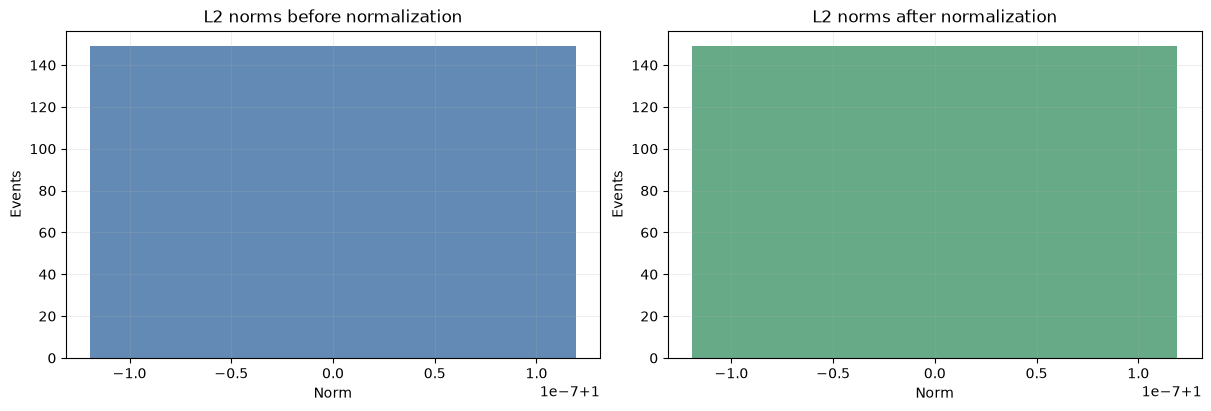

In [6]:
display(pd.DataFrame([{
    'before min': summary['l2_norm_before_min'],
    'before max': summary['l2_norm_before_max'],
    'after min': summary['l2_norm_after_min'],
    'after max': summary['l2_norm_after_max'],
}]))
figure = plot_l2_normalization(evaluation)
display(figure)
plt.close(figure)

## 5. PCA variance retention

The table reports how many components are needed for 90% and 95% cumulative variance. Clustering uses the configured 95% representation.

,target_variance,components,explained_variance
0,90%,49,90.08%
1,95%,73,95.11%


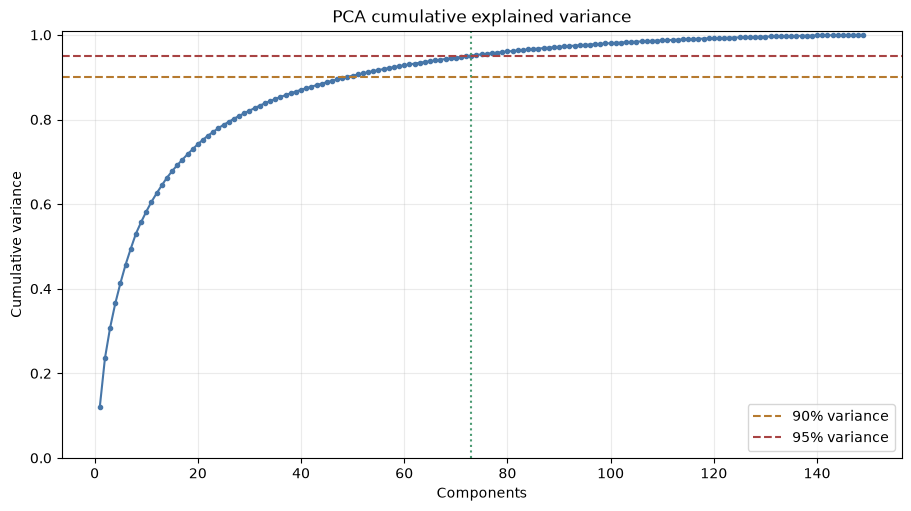

In [7]:
display(pd.DataFrame(evaluation['pca']['rows']).style.format({'target_variance': '{:.0%}', 'explained_variance': '{:.2%}'}))
figure = plot_pca_variance(evaluation)
display(figure)
plt.close(figure)

## 6. Silhouette score

Higher values indicate more compact and better separated K-Means clusters.

,best k,best silhouette
0,3,0.092243


,k,silhouette
0,2,0.0849
1,3,0.0922
2,4,0.0800
3,5,0.0675
4,6,0.0636
5,7,0.0605
6,8,0.0631
7,9,0.0631
8,10,0.0624


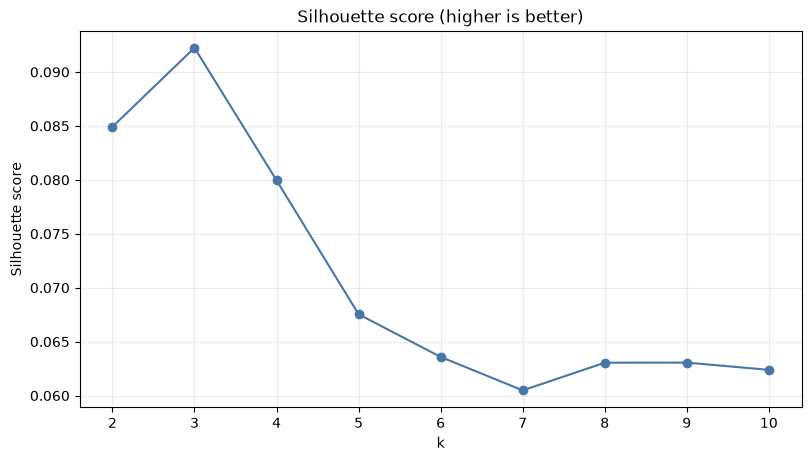

In [8]:
kmeans_metrics = pd.DataFrame(evaluation['kmeans']['rows'])
silhouette_best = kmeans_metrics.loc[kmeans_metrics['silhouette'].idxmax()]
display(pd.DataFrame([{'best k': int(silhouette_best['k']), 'best silhouette': silhouette_best['silhouette']}]))
display(kmeans_metrics[['k', 'silhouette']].style.format({'silhouette': '{:.4f}'}))
figure = plot_kmeans_metric(evaluation, 'silhouette')
display(figure)
plt.close(figure)

## 7. Davies-Bouldin index

Lower values indicate clusters with lower within-cluster scatter relative to between-cluster separation.

,best k,lowest Davies-Bouldin
0,9,2.411964


,k,davies_bouldin
0,2,3.0501
1,3,2.5317
2,4,2.5722
3,5,2.7826
4,6,2.6148
5,7,2.5760
6,8,2.4390
7,9,2.4120
8,10,2.4679


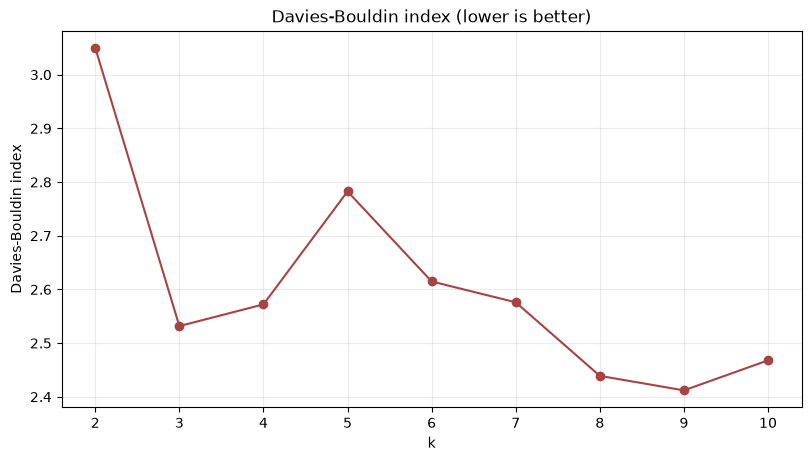

In [9]:
db_best = kmeans_metrics.loc[kmeans_metrics['davies_bouldin'].idxmin()]
display(pd.DataFrame([{'best k': int(db_best['k']), 'lowest Davies-Bouldin': db_best['davies_bouldin']}]))
display(kmeans_metrics[['k', 'davies_bouldin']].style.format({'davies_bouldin': '{:.4f}'}))
figure = plot_kmeans_metric(evaluation, 'davies_bouldin')
display(figure)
plt.close(figure)

## 8. Calinski-Harabasz index

Higher values indicate stronger between-cluster dispersion relative to within-cluster dispersion.

,best k,highest Calinski-Harabasz
0,2,15.207029


,k,calinski_harabasz
0,2,15.21
1,3,14.86
2,4,12.75
3,5,10.90
4,6,9.89
5,7,8.83
6,8,8.32
7,9,7.89
8,10,7.46


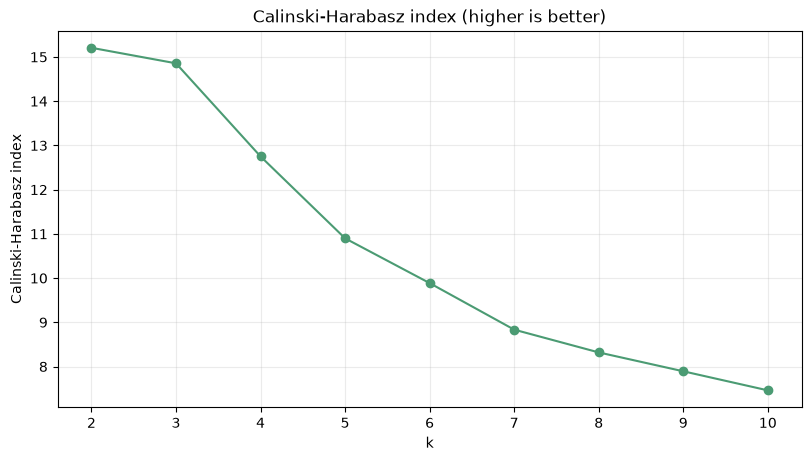

In [10]:
ch_best = kmeans_metrics.loc[kmeans_metrics['calinski_harabasz'].idxmax()]
display(pd.DataFrame([{'best k': int(ch_best['k']), 'highest Calinski-Harabasz': ch_best['calinski_harabasz']}]))
display(kmeans_metrics[['k', 'calinski_harabasz']].style.format({'calinski_harabasz': '{:.2f}'}))
figure = plot_kmeans_metric(evaluation, 'calinski_harabasz')
display(figure)
plt.close(figure)

## 9. Cluster stability

For every k, K-Means is refit on repeated 80% event subsamples. The Adjusted Rand Index compares each subsampled model, predicted over all events, with the full-data reference solution. Higher mean ARI and lower standard deviation indicate a more stable structure.

,best k,mean ARI,ARI std
0,3,0.844072,0.085237


,k,runs,sample_fraction,subset_size,ari_mean,ari_std,ari_min,ari_max
0,2,20,80%,119,0.6173,0.3516,0.0426,0.9732
1,3,20,80%,119,0.8441,0.0852,0.5897,0.9687
2,4,20,80%,119,0.8015,0.0732,0.6762,0.9217
3,5,20,80%,119,0.5233,0.0757,0.3851,0.6578
4,6,20,80%,119,0.4153,0.0768,0.2406,0.5393
5,7,20,80%,119,0.4033,0.0668,0.2977,0.5498
6,8,20,80%,119,0.3777,0.0706,0.3093,0.6089
7,9,20,80%,119,0.4063,0.0696,0.2881,0.5558
8,10,20,80%,119,0.3749,0.0937,0.2398,0.5733


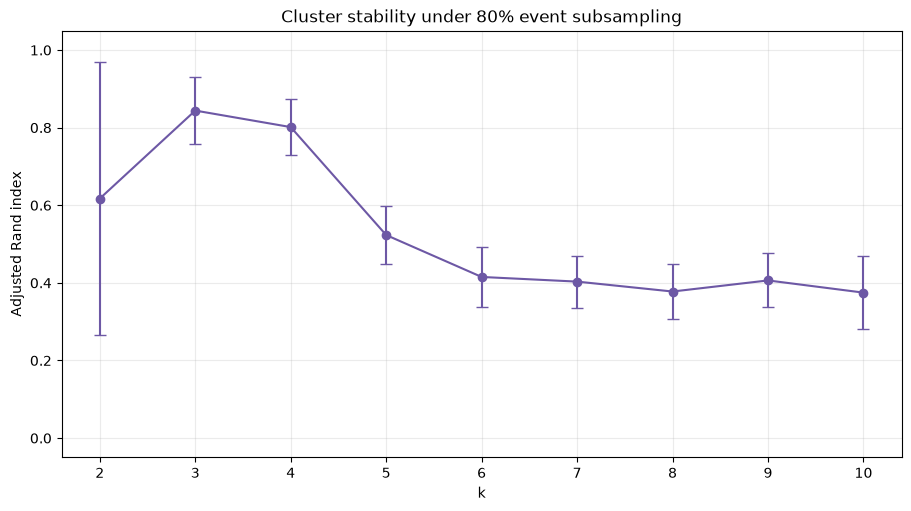

In [11]:
stability = pd.DataFrame(evaluation['stability']['rows'])
stability_best = stability.loc[stability['ari_mean'].idxmax()]
display(pd.DataFrame([{'best k': int(stability_best['k']), 'mean ARI': stability_best['ari_mean'], 'ARI std': stability_best['ari_std']}]))
display(stability.style.format({'sample_fraction': '{:.0%}', 'ari_mean': '{:.4f}', 'ari_std': '{:.4f}', 'ari_min': '{:.4f}', 'ari_max': '{:.4f}'}))
figure = plot_cluster_stability(evaluation)
display(figure)
plt.close(figure)

## 10. Gaussian mixture BIC

BIC balances likelihood and model complexity. The preferred component count has the lowest BIC; AIC is shown as a secondary diagnostic.

,best components by BIC,BIC,converged
0,3,-28918.549143,True


,k,bic,aic,converged,iterations
0,1,-28358.75,-36691.69,True,2
1,2,-25601.27,-42270.16,True,2
2,3,-28918.55,-53923.40,True,2
3,4,-26825.37,-60166.17,True,2
4,5,-20466.12,-62142.87,True,2
5,6,-9955.11,-59967.82,True,2
6,7,-1498.91,-59847.57,True,2
7,8,8331.08,-58353.52,True,2
8,9,19863.87,-55156.69,True,2
9,10,31637.12,-51719.39,True,2


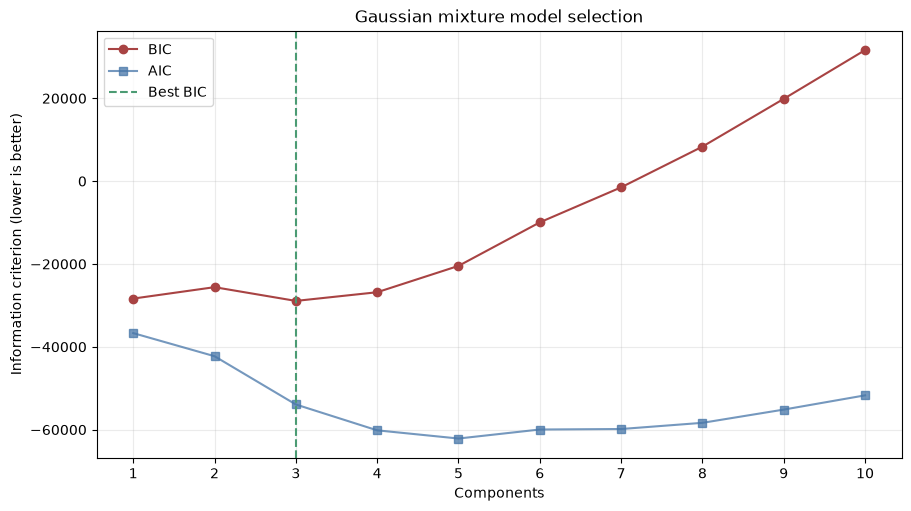

In [12]:
gmm = pd.DataFrame(evaluation['gmm']['rows'])
gmm_best = gmm.loc[gmm['bic'].idxmin()]
display(pd.DataFrame([{'best components by BIC': int(gmm_best['k']), 'BIC': gmm_best['bic'], 'converged': bool(gmm_best['converged'])}]))
display(gmm.style.format({'bic': '{:.2f}', 'aic': '{:.2f}'}))
figure = plot_gmm_bic(evaluation)
display(figure)
plt.close(figure)

## 11. HDBSCAN density structure

The parameter sweep varies `min_cluster_size` and `min_samples`. Selection maximizes `silhouette on clustered events × non-noise coverage`; noise is kept explicit rather than forced into a cluster. The PCA scatter is for visualization only—the model uses the full retained PCA representation.

,key,min_cluster_size,min_samples,clusters,noise_points,noise_fraction,coverage,silhouette_clustered,membership_mean,selection_score
0,mcs=3;ms=1,3,1,3,49,32.9%,67.1%,0.0822,0.968688,0.0552


,key,min_cluster_size,min_samples,clusters,noise_points,noise_fraction,coverage,silhouette_clustered,membership_mean,selection_score
1,mcs=3;ms=1,3,1.000000,3,49,32.9%,67.1%,0.0822,0.968688,0.0552
2,mcs=3;ms=2,3,2.000000,3,49,32.9%,67.1%,0.0822,0.968688,0.0552
6,mcs=5;ms=2,5,2.000000,2,105,70.5%,29.5%,0.1809,0.886639,0.0534
5,mcs=5;ms=1,5,1.000000,2,105,70.5%,29.5%,0.1809,0.886639,0.0534
0,mcs=3;ms=None,3,nan,2,118,79.2%,20.8%,0.1925,0.888503,0.0400
3,mcs=3;ms=3,3,3.000000,2,118,79.2%,20.8%,0.1925,0.888503,0.0400
4,mcs=5;ms=None,5,nan,0,149,100.0%,0.0%,nan,0.000000,-1.0000
7,mcs=5;ms=3,5,3.000000,0,149,100.0%,0.0%,nan,0.000000,-1.0000
8,mcs=5;ms=5,5,5.000000,0,149,100.0%,0.0%,nan,0.000000,-1.0000
9,mcs=7;ms=None,7,nan,0,149,100.0%,0.0%,nan,0.000000,-1.0000


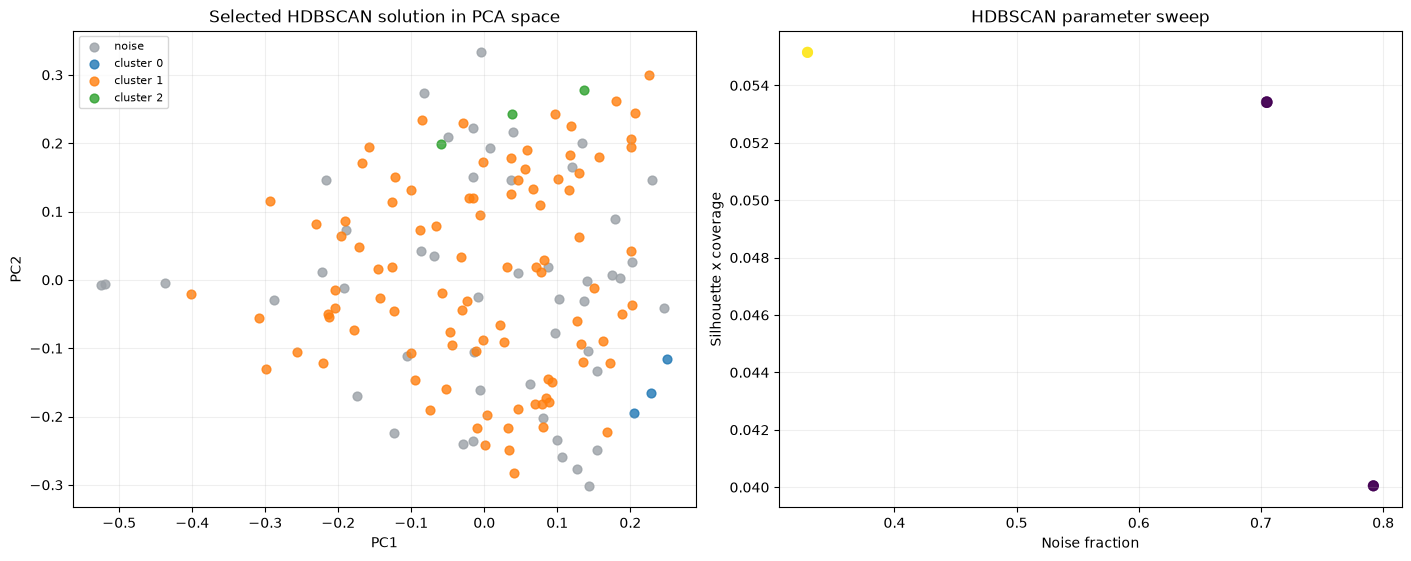

In [13]:
hdbscan_sweep = pd.DataFrame(evaluation['hdbscan']['rows']).sort_values('selection_score', ascending=False)
display(pd.DataFrame([evaluation['hdbscan']['selected']]).style.format({'noise_fraction': '{:.1%}', 'coverage': '{:.1%}', 'silhouette_clustered': '{:.4f}', 'selection_score': '{:.4f}'}))
display(hdbscan_sweep.head(12).style.format({'noise_fraction': '{:.1%}', 'coverage': '{:.1%}', 'silhouette_clustered': '{:.4f}', 'selection_score': '{:.4f}'}))
figure = plot_hdbscan(evaluation)
display(figure)
plt.close(figure)

## 12. Final summary and cluster composition

No single index proves a true number of natural groups. The summary therefore keeps every criterion visible and uses the median K-Means vote only as a stable reference solution. Logging/Wildfire composition is descriptive and does not make the clustering supervised.

,structure signal,best silhouette,best stability ARI,reference K-Means k,HDBSCAN clusters,HDBSCAN noise
0,weak separation,0.0922,0.8441,3,3,32.9%


,criterion,suggested k
0,Silhouette maximum,3
1,Davies-Bouldin minimum,9
2,Calinski-Harabasz maximum,2
3,Subsample stability maximum,3
4,GMM BIC minimum,3
5,Reference K-Means median vote,3


,method,cluster,cluster_name,label,events,cluster_events,cluster_share
0,KMeans k=3,0,0,Logging,45,45,100.0%
1,KMeans k=3,1,1,Logging,8,68,11.8%
2,KMeans k=3,1,1,Wildfire,60,68,88.2%
3,KMeans k=3,2,2,Logging,26,36,72.2%
4,KMeans k=3,2,2,Wildfire,10,36,27.8%


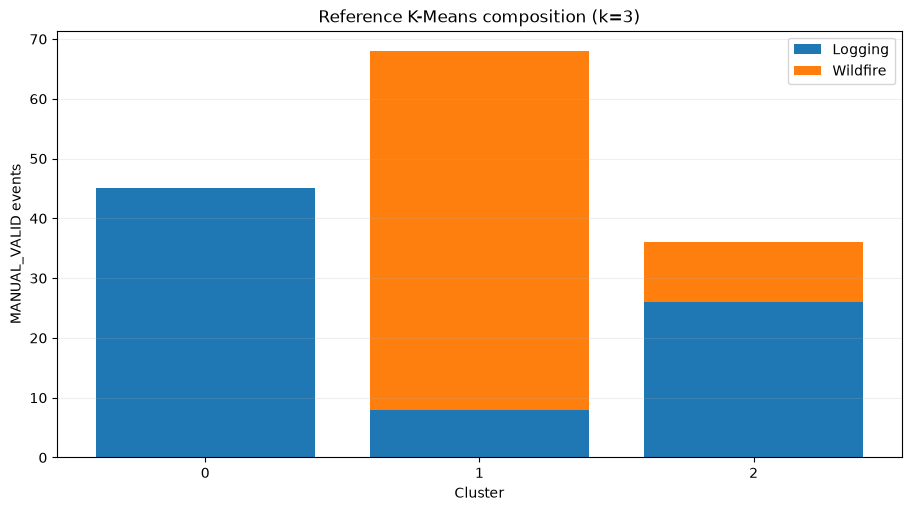

In [14]:
decision_summary = pd.DataFrame([
    {'criterion': 'Silhouette maximum', 'suggested k': summary['silhouette_k']},
    {'criterion': 'Davies-Bouldin minimum', 'suggested k': summary['davies_bouldin_k']},
    {'criterion': 'Calinski-Harabasz maximum', 'suggested k': summary['calinski_harabasz_k']},
    {'criterion': 'Subsample stability maximum', 'suggested k': summary['stability_k']},
    {'criterion': 'GMM BIC minimum', 'suggested k': summary['gmm_bic_k']},
    {'criterion': 'Reference K-Means median vote', 'suggested k': summary['reference_kmeans_k']},
])
display(pd.DataFrame([{
    'structure signal': summary['structure_signal'],
    'best silhouette': summary['best_silhouette'],
    'best stability ARI': summary['best_stability_ari'],
    'reference K-Means k': summary['reference_kmeans_k'],
    'HDBSCAN clusters': summary['hdbscan_selected']['clusters'],
    'HDBSCAN noise': summary['hdbscan_selected']['noise_fraction'],
}]).style.format({'best silhouette': '{:.4f}', 'best stability ARI': '{:.4f}', 'HDBSCAN noise': '{:.1%}'}))
display(decision_summary)
display(pd.DataFrame(evaluation['kmeans_composition']).style.format({'cluster_share': '{:.1%}'}))
figure = plot_cluster_composition(evaluation)
display(figure)
plt.close(figure)

## 13. Frozen-model diagnostics setup

The following sections reconstruct the current `MANUAL_VALID + PRE_POST` reference cohort and audit its event-id hash against the frozen `REMOTECLIP_LOGREG/v1` training manifest. A mismatch is shown explicitly but does not retrain or modify the frozen model. Clusters still come from the POST-only latent map; LogReg probabilities come from the existing production artifact.

The current MANUAL_VALID PRE_POST event-id set differs from the historical production training set; probabilities still use the frozen artifact.


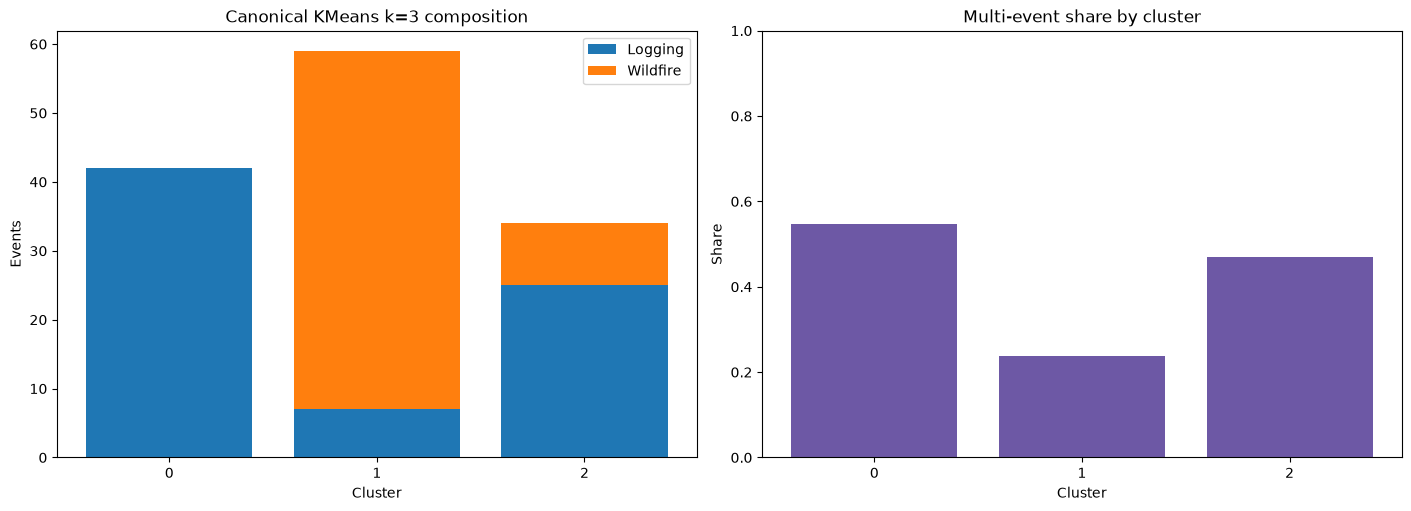

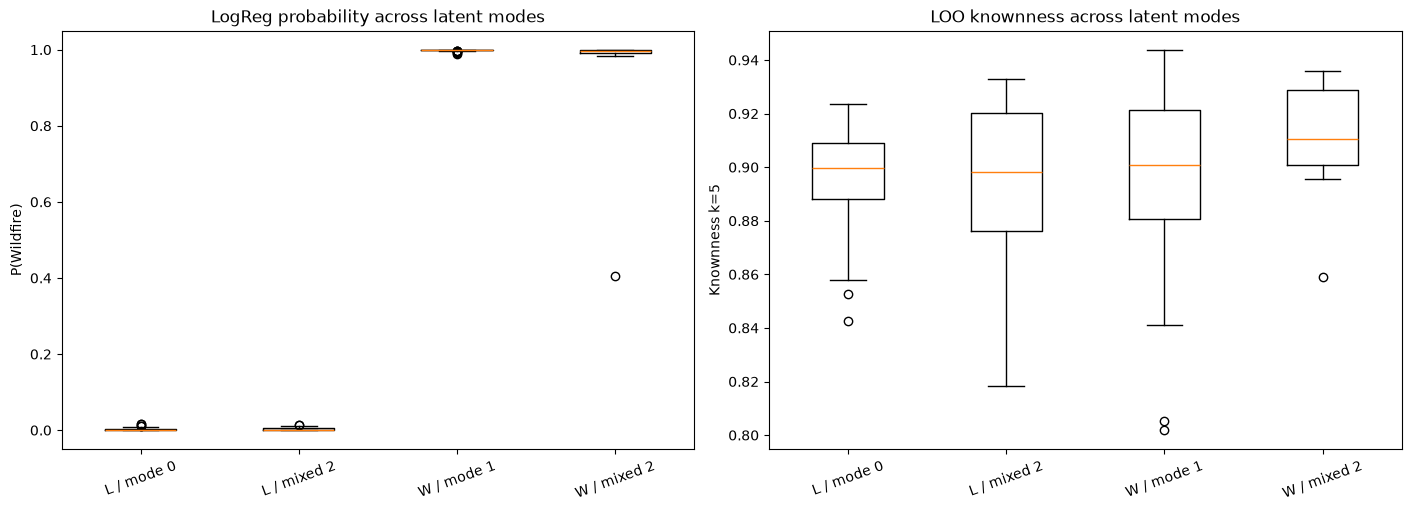

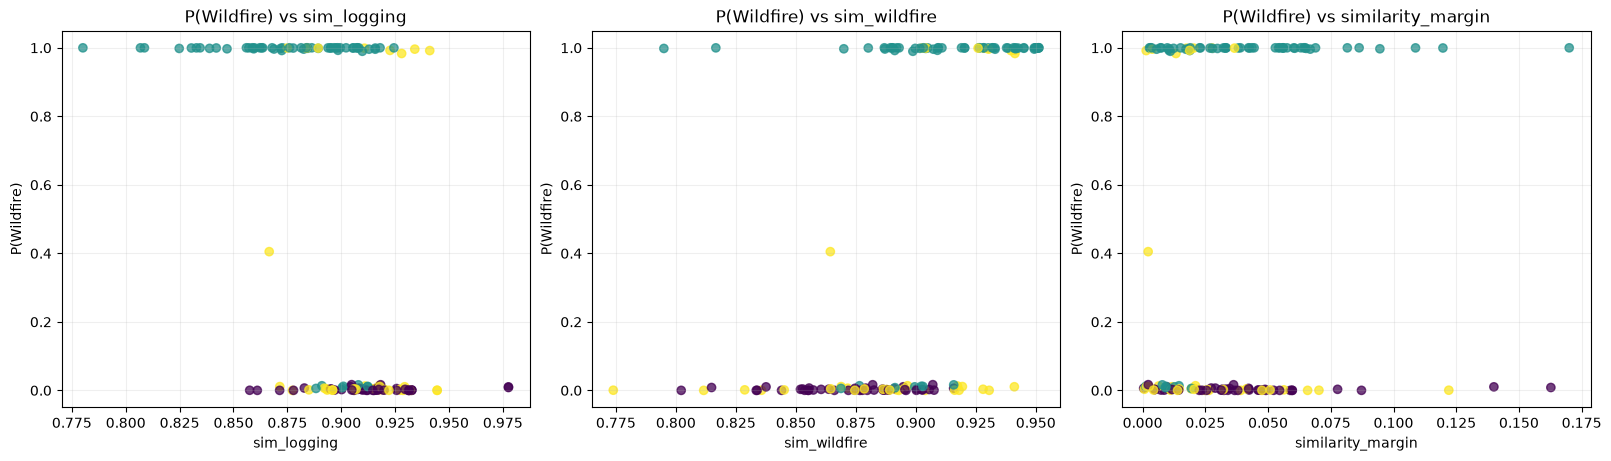

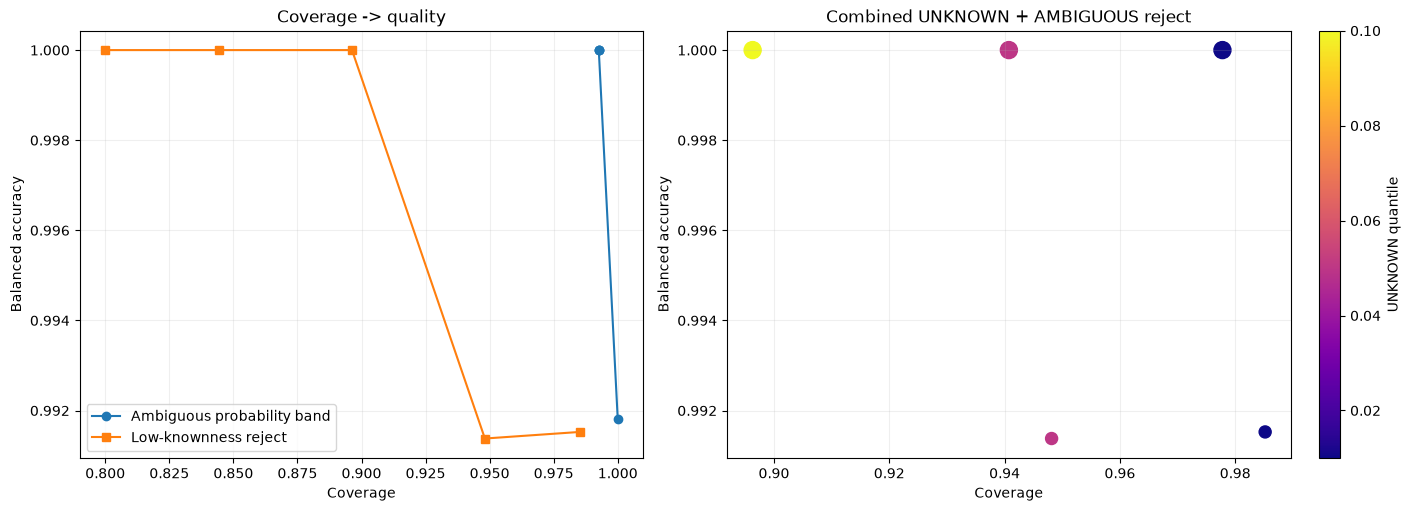

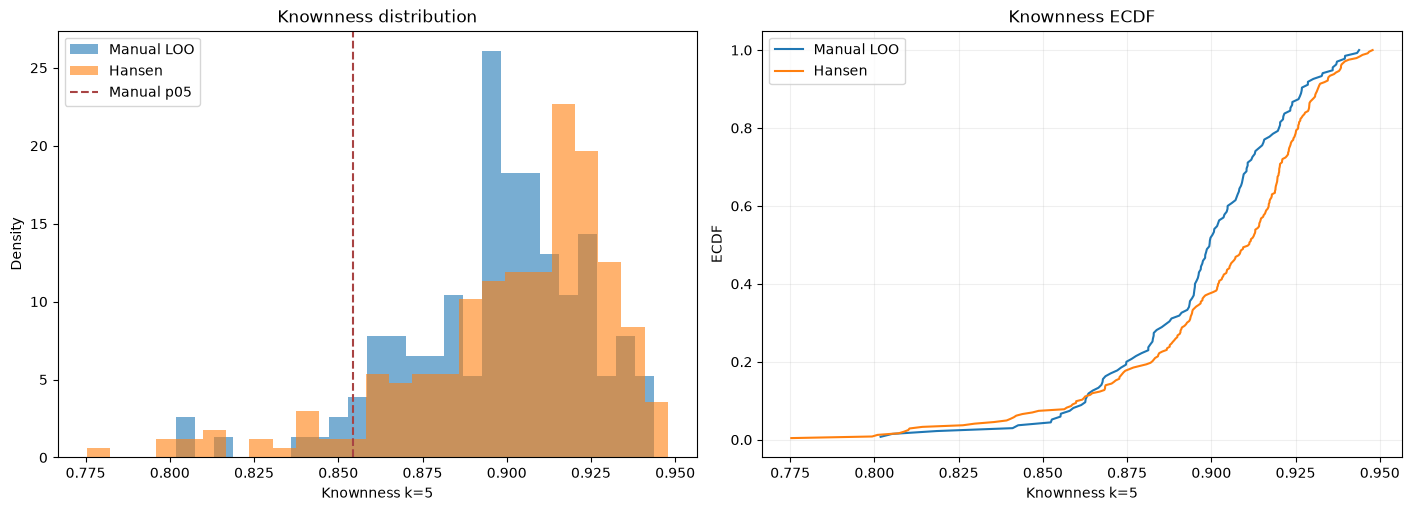

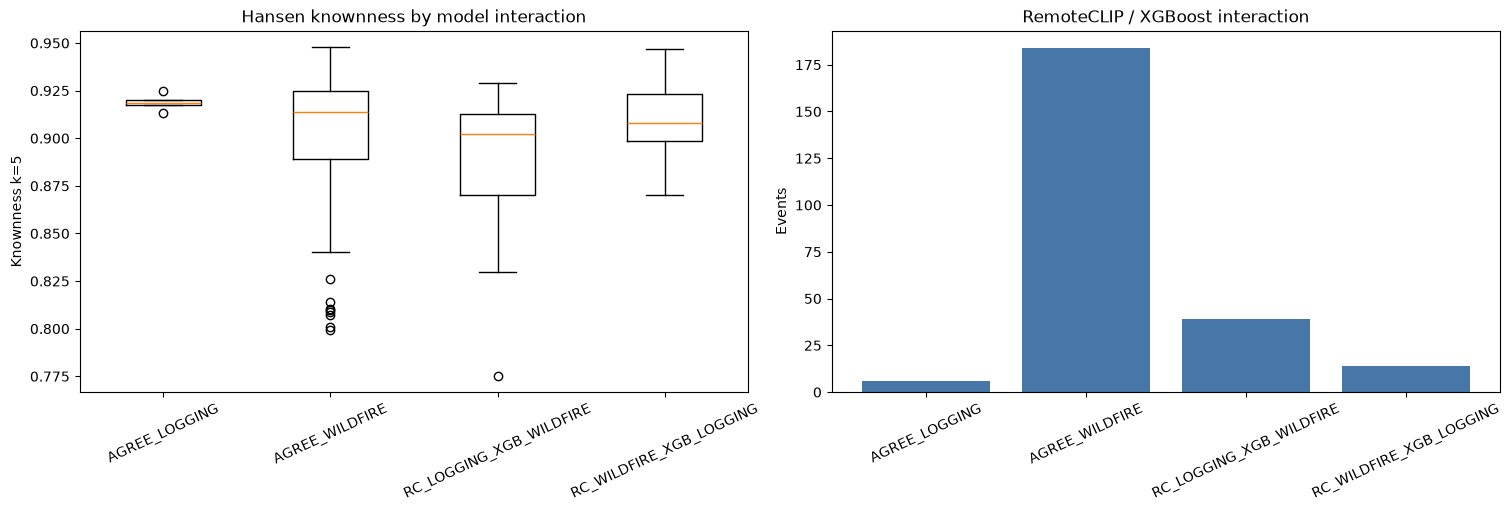

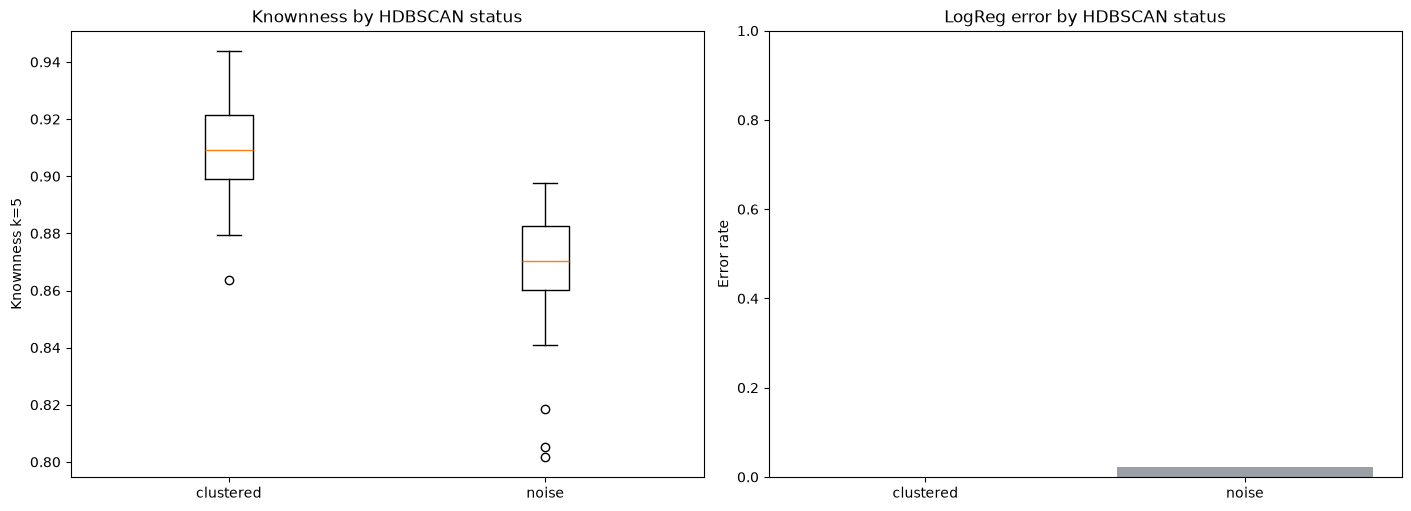

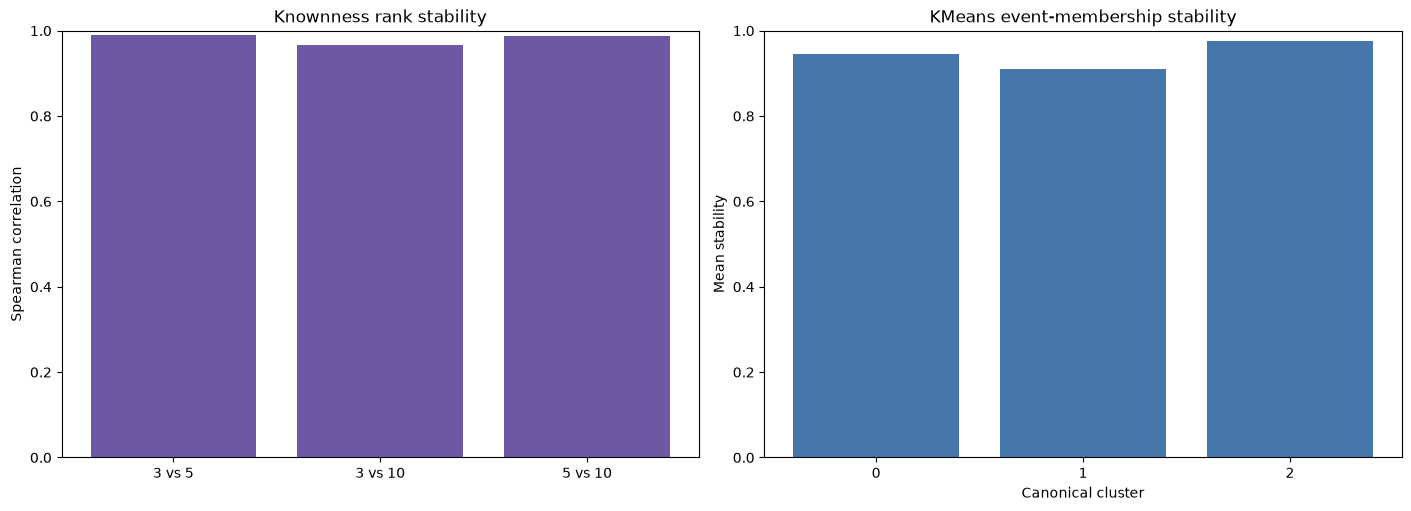

In [15]:
diagnostics = pipeline.run_latent_diagnostics(
    manifest,
    embeddings,
    evaluation,
    remoteclip_version=REMOTECLIP_VERSION,
    reference_k=3,
    membership_runs=MEMBERSHIP_STABILITY_RUNS,
    membership_sample_fraction=STABILITY_SAMPLE_FRACTION,
    random_state=RANDOM_STATE,
)
diagnostic_summary = diagnostics['summary']
diagnostic_plots = diagnostic_figures(diagnostics)
pd.DataFrame([{
    'current manual reference events': diagnostic_summary['current_reference_events'],
    'historical production train events': diagnostic_summary['production_training_events'],
    'Hansen-mined events': diagnostic_summary['hansen_mined_events'],
    'exact production cohort': diagnostic_summary['exact_production_training_cohort'],
    'RemoteCLIP feature': diagnostic_summary['remoteclip_feature_variant'],
}])
print(diagnostic_summary['cohort_audit_note'])

## 14. Cluster × label × season and multi-event structure

K-Means identifiers are canonicalized only after unsupervised fitting: cluster 0 is the most Logging-pure mode, cluster 1 is the most Wildfire-pure remaining mode, and cluster 2 is the mixed mode. Raw IDs are retained in every export.

,kmeans_cluster_raw,kmeans_cluster,cluster_role,events,logging_events,wildfire_events,logging_share,wildfire_share
0,0,0,logging_mode,45,45,0,100.0%,0.0%
1,1,1,wildfire_mode,68,8,60,11.8%,88.2%
2,2,2,mixed_mode,36,26,10,72.2%,27.8%


season                     early_summer  late_summer  outside_defined_seasons  \
kmeans_cluster true_label                                                       
0              Logging               28            3                        9   
1              Logging                4            3                        0   
               Wildfire              21           13                        7   
2              Logging                8           14                        1   
               Wildfire               3            5                        1   

season                     spring  
kmeans_cluster true_label          
0              Logging          2  
1              Logging          0  
               Wildfire        11  
2              Logging          2  
               Wildfire         0

is_multi_event_area        False  True 
kmeans_cluster true_label              
0              Logging        19     23
1              Logging         3      4
               Wildfire       42     10
2              Logging        11     14
               Wildfire        7      2

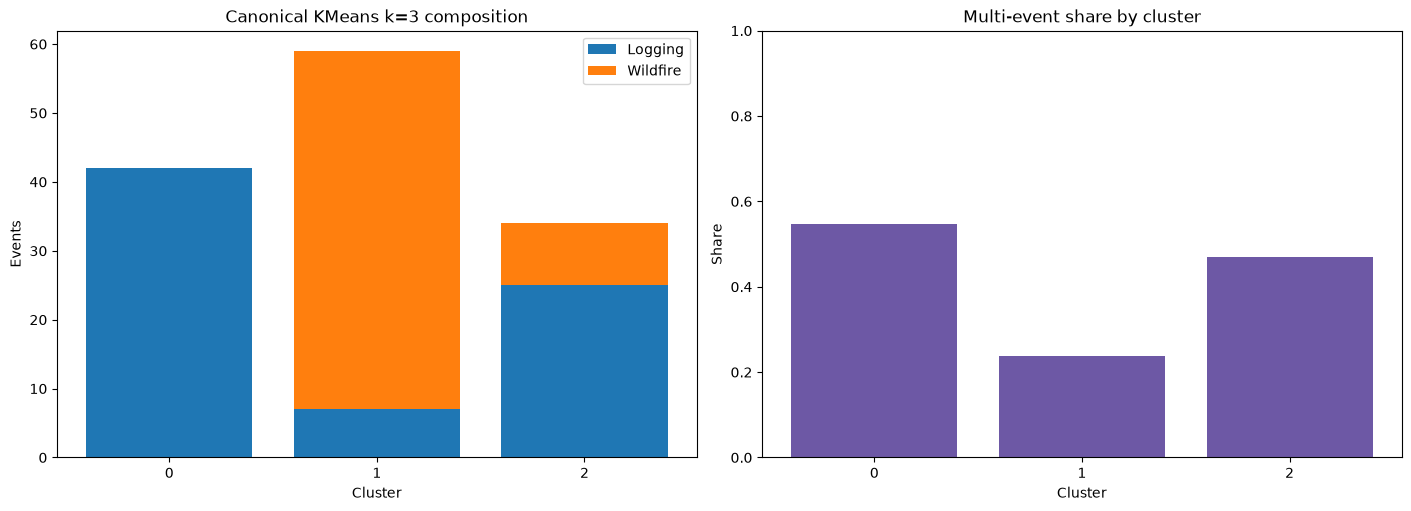

In [16]:
display(pd.DataFrame(diagnostics['cluster_roles']).style.format({'logging_share': '{:.1%}', 'wildfire_share': '{:.1%}'}))
display(pd.DataFrame(diagnostics['cluster_label_season']).pivot_table(index=['kmeans_cluster', 'true_label'], columns='season', values='events', aggfunc='sum', fill_value=0))
display(pd.DataFrame(diagnostics['cluster_label_multi_event']).pivot_table(index=['kmeans_cluster', 'true_label'], columns='is_multi_event_area', values='events', aggfunc='sum', fill_value=0))
display(diagnostic_plots['cluster_metadata'])
plt.close(diagnostic_plots['cluster_metadata'])

## 15. Pure and mixed latent modes within each class

Logging cluster 0 is compared with Logging cluster 2, and Wildfire cluster 1 with Wildfire cluster 2. The table includes season, event year, PRE/POST support, multi-event history, Hansen area, LogReg probability, and knownness.

,group,metric,events,mean,median,p25,p75
0,Logging / logging mode,multi_event_rate,42,0.5476,nan,nan,nan
1,Logging / logging mode,event_year,42,2021.3810,2022.0000,2019.0000,2024.0000
2,Logging / logging mode,event_loss_area_ha,42,12.5026,10.0327,5.3410,17.0812
3,Logging / logging mode,pre_image_count,42,3.1190,2.5000,2.0000,4.7500
4,Logging / logging mode,post_image_count,42,3.1429,3.0000,2.0000,4.0000
5,Logging / logging mode,hansen_event_count,42,2.9762,3.0000,2.0000,4.0000
6,Logging / logging mode,hansen_total_loss_area_ha,42,18.2606,11.7900,6.5750,26.2178
7,Logging / logging mode,logreg_probability_wildfire,42,0.0031,0.0010,0.0002,0.0040
8,Logging / logging mode,knownness_k5,42,0.8961,0.8996,0.8883,0.9090
9,Logging / logging mode,similarity_margin,42,0.0395,0.0343,0.0228,0.0485


,group,season,events,share
0,Logging / logging mode,early_summer,28,66.7%
1,Logging / logging mode,late_summer,3,7.1%
2,Logging / logging mode,outside_defined_seasons,9,21.4%
3,Logging / logging mode,spring,2,4.8%
4,Logging / mixed mode,early_summer,8,32.0%
5,Logging / mixed mode,late_summer,14,56.0%
6,Logging / mixed mode,outside_defined_seasons,1,4.0%
7,Logging / mixed mode,spring,2,8.0%
8,Wildfire / wildfire mode,early_summer,21,40.4%
9,Wildfire / wildfire mode,late_summer,13,25.0%


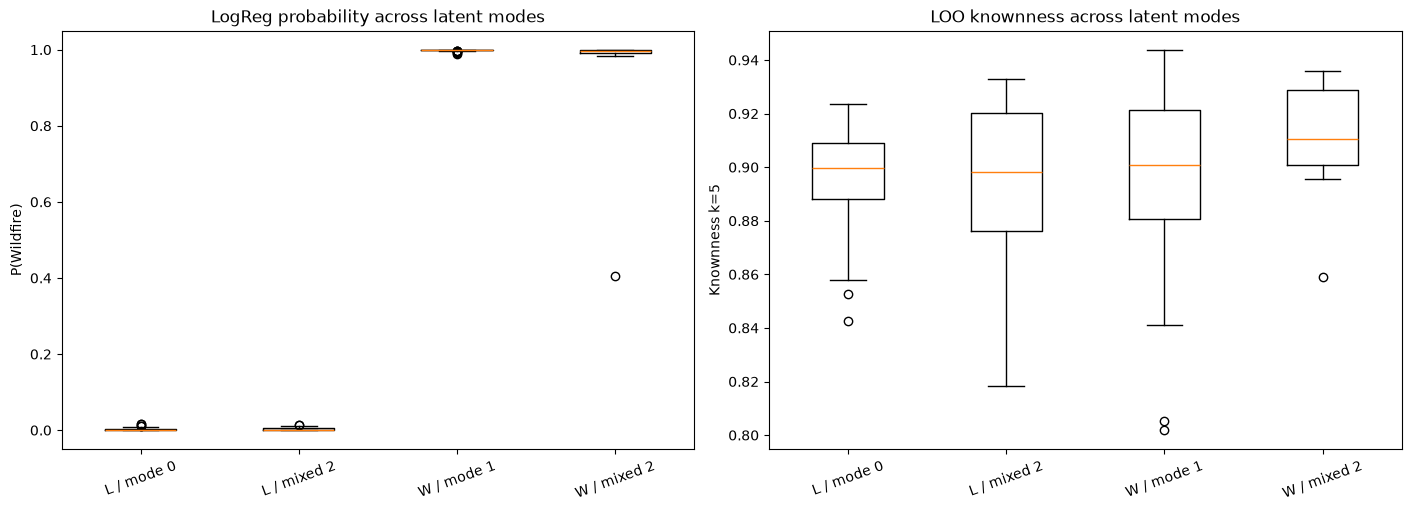

In [17]:
mode_comparison = pd.DataFrame(diagnostics['mode_comparison'])
display(mode_comparison.style.format({'mean': '{:.4f}', 'median': '{:.4f}', 'p25': '{:.4f}', 'p75': '{:.4f}'}))
display(pd.DataFrame(diagnostics['mode_seasons']).style.format({'share': '{:.1%}'}))
display(diagnostic_plots['latent_mode_comparison'])
plt.close(diagnostic_plots['latent_mode_comparison'])

## 16. Leave-one-out kNN knownness

Each manual train event is removed from its own neighbour set. The empirical p01..p99 distributions for `k=3,5,10` describe normal train-space density without declaring an UNKNOWN threshold.

In [18]:
loo_quantiles = pd.DataFrame(diagnostics['loo_quantiles'])
display(loo_quantiles.pivot(index='quantile', columns='metric', values='value').style.format('{:.5f}'))
display(pd.DataFrame(diagnostics['manual_rows'])[['event_id', 'true_label', 'nearest_similarity', 'knownness_k3', 'knownness_k5', 'knownness_k10']].head(15))

metric,knownness_k10,knownness_k3,knownness_k5
quantile,,,
0.010000,0.79754,0.81940,0.80975
0.050000,0.83890,0.86360,0.85445
0.100000,0.85211,0.87082,0.86285
0.250000,0.87252,0.88901,0.88259
0.500000,0.89174,0.90437,0.89950
0.750000,0.90677,0.92001,0.91457
0.900000,0.91876,0.93209,0.92686
0.950000,0.92753,0.93866,0.93602
0.990000,0.93357,0.94626,0.94205


,event_id,true_label,nearest_similarity,knownness_k3,knownness_k5,knownness_k10
0,f0ea8245f0e531ddf93a9efbd9dfdfd70c78d29e,Wildfire,0.928257,0.915406,0.909604,0.899009
1,9db54f6a5d220c39ea506e4bafd413b09b083779,Wildfire,0.892062,0.884768,0.877653,0.866485
2,99c9f3e316febfea8141f579cbb8886e2494d2a8,Wildfire,0.926428,0.909613,0.904804,0.895543
3,0dcf70a85c9be384bd23dcfdee590d5c484047a8,Wildfire,0.866569,0.862918,0.859048,0.846478
4,42868dae7542a4b917b4764815a342474e7468c4,Wildfire,0.941059,0.938516,0.936007,0.929928
5,7a2033025cb30d007f309d8c947457ff57c535cc,Logging,0.915158,0.911763,0.909407,0.904757
6,d567025fc66305761627192faf469d6905c9fe26,Wildfire,0.949383,0.926924,0.917272,0.903792
7,7233ce5ad3a5bbdbcc13e990ee3cb6ea4ea190e6,Logging,0.928745,0.923224,0.920394,0.912541
8,9e8f8d68ce5f4f35595c51d17be23f0e3554b54f,Logging,0.916171,0.913424,0.912211,0.909193
9,42d5f846cc3f7c9043b94c81f3c7538a9c62a19d,Wildfire,0.937833,0.929734,0.924048,0.916020


## 17. Class-conditional neighbours

Nearest Logging and Wildfire similarities provide a local non-parametric prediction and a similarity margin. This is compared with the true label and the frozen LogReg decision.

In [19]:
display(pd.DataFrame([diagnostic_summary['manual_nearest_class_metrics'] | {
    'nearest-class vs LogReg agreement': diagnostic_summary['manual_nearest_class_vs_logreg_agreement'],
}]).style.format({column: '{:.3f}' for column in ['accuracy', 'balanced_accuracy', 'logging_precision', 'logging_recall', 'wildfire_precision', 'wildfire_recall', 'nearest-class vs LogReg agreement']}))
display(pd.DataFrame(diagnostics['manual_rows'])[['event_id', 'true_label', 'sim_logging', 'sim_wildfire', 'similarity_margin', 'nearest_class_prediction', 'remoteclip_prediction']].head(15))

,evaluated_events,accuracy,balanced_accuracy,logging_precision,logging_recall,wildfire_precision,wildfire_recall,nearest-class vs LogReg agreement
0,135,0.896,0.895,0.905,0.905,0.885,0.885,0.904


,event_id,true_label,sim_logging,sim_wildfire,similarity_margin,nearest_class_prediction,remoteclip_prediction
0,f0ea8245f0e531ddf93a9efbd9dfdfd70c78d29e,Wildfire,0.910759,0.928257,0.017498,Wildfire,Wildfire
1,9db54f6a5d220c39ea506e4bafd413b09b083779,Wildfire,0.834496,0.892062,0.057565,Wildfire,Wildfire
2,99c9f3e316febfea8141f579cbb8886e2494d2a8,Wildfire,0.862195,0.926428,0.064234,Wildfire,Wildfire
3,0dcf70a85c9be384bd23dcfdee590d5c484047a8,Wildfire,0.866569,0.864363,0.002205,Logging,Logging
4,42868dae7542a4b917b4764815a342474e7468c4,Wildfire,0.941059,0.939638,0.001421,Logging,Wildfire
5,7a2033025cb30d007f309d8c947457ff57c535cc,Logging,0.915158,0.866049,0.049109,Logging,Logging
6,d567025fc66305761627192faf469d6905c9fe26,Wildfire,0.882571,0.949383,0.066812,Wildfire,Wildfire
7,7233ce5ad3a5bbdbcc13e990ee3cb6ea4ea190e6,Logging,0.928745,0.903928,0.024818,Logging,Logging
8,9e8f8d68ce5f4f35595c51d17be23f0e3554b54f,Logging,0.916171,0.907592,0.008579,Logging,Logging
9,42d5f846cc3f7c9043b94c81f3c7538a9c62a19d,Wildfire,0.905598,0.937833,0.032235,Wildfire,Wildfire


## 18. LogReg probability and latent structure

This section tests whether the mixed cluster is concentrated near `P(Wildfire)=0.5` and whether class similarity or margin tracks the classifier confidence.

,kmeans_cluster,events,probability_mean,probability_median,probability_p25,probability_p75,central_0_4_0_6_share
0,0,42,0.0031,0.0010,0.0002,0.0040,0.0%
1,1,59,0.8816,0.9998,0.9971,0.9999,0.0%
2,2,34,0.2488,0.0044,0.0007,0.3071,2.9%


,metric,spearman_correlation,p_value
0,sim_logging,-0.5102,2.6e-10
1,sim_wildfire,0.5967,2.21e-14
2,similarity_margin,0.0329,0.705


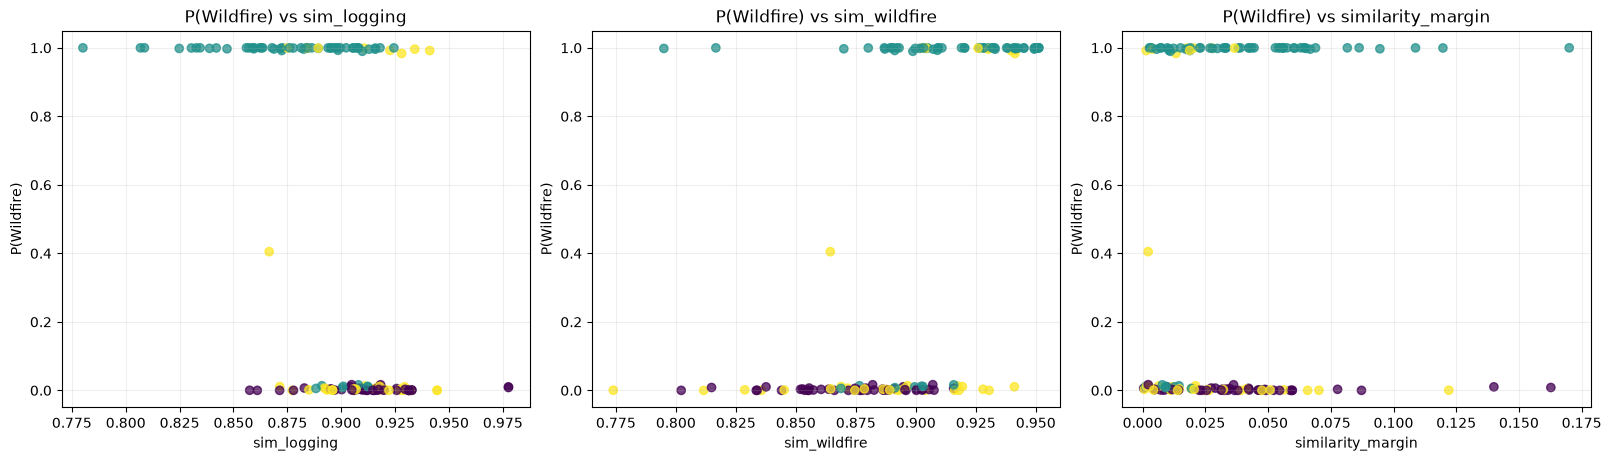

In [20]:
display(pd.DataFrame(diagnostics['probability_by_cluster']).style.format({'probability_mean': '{:.4f}', 'probability_median': '{:.4f}', 'probability_p25': '{:.4f}', 'probability_p75': '{:.4f}', 'central_0_4_0_6_share': '{:.1%}'}))
display(pd.DataFrame(diagnostics['probability_correlations']).style.format({'spearman_correlation': '{:.4f}', 'p_value': '{:.3g}'}))
display(diagnostic_plots['probability_relations'])
plt.close(diagnostic_plots['probability_relations'])

## 19. AMBIGUOUS probability bands

Central probability bands are rejected one by one. Coverage is the fraction still assigned Logging/Wildfire; quality is measured only on retained events.

In [21]:
display(pd.DataFrame(diagnostics['ambiguity_reject']).style.format({'coverage': '{:.1%}', 'accuracy': '{:.3f}', 'balanced_accuracy': '{:.3f}', 'logging_precision': '{:.3f}', 'logging_recall': '{:.3f}', 'wildfire_precision': '{:.3f}', 'wildfire_recall': '{:.3f}'}))

,ambiguous_lower,ambiguous_upper,ambiguous_events,coverage,rejected_events,evaluated_events,accuracy,balanced_accuracy,logging_precision,logging_recall,wildfire_precision,wildfire_recall
0,0.450000,0.550000,0,100.0%,0,135,0.993,0.992,0.987,1.000,1.000,0.984
1,0.400000,0.600000,1,99.3%,1,134,1.000,1.000,1.000,1.000,1.000,1.000
2,0.350000,0.650000,1,99.3%,1,134,1.000,1.000,1.000,1.000,1.000,1.000
3,0.300000,0.700000,1,99.3%,1,134,1.000,1.000,1.000,1.000,1.000,1.000


## 20. Knownness reject

The lowest 1%, 5%, 10%, 15%, and 20% of manual LOO knownness are removed to test whether sparse latent regions carry more LogReg errors.

In [22]:
display(pd.DataFrame(diagnostics['knownness_reject']).style.format({'reject_fraction_target': '{:.0%}', 'knownness_threshold': '{:.5f}', 'coverage': '{:.1%}', 'accuracy': '{:.3f}', 'balanced_accuracy': '{:.3f}'}))

,knownness_metric,reject_fraction_target,knownness_threshold,coverage,rejected_events,evaluated_events,accuracy,balanced_accuracy,logging_precision,logging_recall,wildfire_precision,wildfire_recall
0,knownness_k5,1%,0.80975,98.5%,2,133,0.992,0.992,0.986667,1.000000,1.000000,0.983051
1,knownness_k5,5%,0.85445,94.8%,7,128,0.992,0.991,0.985915,1.000000,1.000000,0.982759
2,knownness_k5,10%,0.86285,89.6%,14,121,1.000,1.000,1.000000,1.000000,1.000000,1.000000
3,knownness_k5,15%,0.86790,84.4%,21,114,1.000,1.000,1.000000,1.000000,1.000000,1.000000
4,knownness_k5,20%,0.87603,80.0%,27,108,1.000,1.000,1.000000,1.000000,1.000000,1.000000


## 21. Combined UNKNOWN and AMBIGUOUS reject

UNKNOWN is evaluated first from manual LOO knownness; AMBIGUOUS is then applied only to in-distribution events. The grid is diagnostic and is never fitted on Hansen candidates. Manual LogReg probabilities are produced by the frozen full-fit artifact, so these quality numbers are descriptive and optimistic; grouped-CV remains the unbiased model estimate.

,knownness_metric,unknown_quantile,knownness_threshold,ambiguous_lower,ambiguous_upper,unknown_events,ambiguous_events,coverage,rejected_events,evaluated_events,accuracy,balanced_accuracy,logging_precision,logging_recall,wildfire_precision,wildfire_recall
0,knownness_k5,1%,0.80975,0.450000,0.550000,2,0,98.5%,2,133,0.992,0.992,0.987,1.000,1.000,0.983
1,knownness_k5,1%,0.80975,0.400000,0.600000,2,1,97.8%,3,132,1.000,1.000,1.000,1.000,1.000,1.000
2,knownness_k5,1%,0.80975,0.350000,0.650000,2,1,97.8%,3,132,1.000,1.000,1.000,1.000,1.000,1.000
3,knownness_k5,1%,0.80975,0.300000,0.700000,2,1,97.8%,3,132,1.000,1.000,1.000,1.000,1.000,1.000
4,knownness_k5,5%,0.85445,0.450000,0.550000,7,0,94.8%,7,128,0.992,0.991,0.986,1.000,1.000,0.983
5,knownness_k5,5%,0.85445,0.400000,0.600000,7,1,94.1%,8,127,1.000,1.000,1.000,1.000,1.000,1.000
6,knownness_k5,5%,0.85445,0.350000,0.650000,7,1,94.1%,8,127,1.000,1.000,1.000,1.000,1.000,1.000
7,knownness_k5,5%,0.85445,0.300000,0.700000,7,1,94.1%,8,127,1.000,1.000,1.000,1.000,1.000,1.000
8,knownness_k5,10%,0.86285,0.450000,0.550000,14,0,89.6%,14,121,1.000,1.000,1.000,1.000,1.000,1.000
9,knownness_k5,10%,0.86285,0.400000,0.600000,14,0,89.6%,14,121,1.000,1.000,1.000,1.000,1.000,1.000


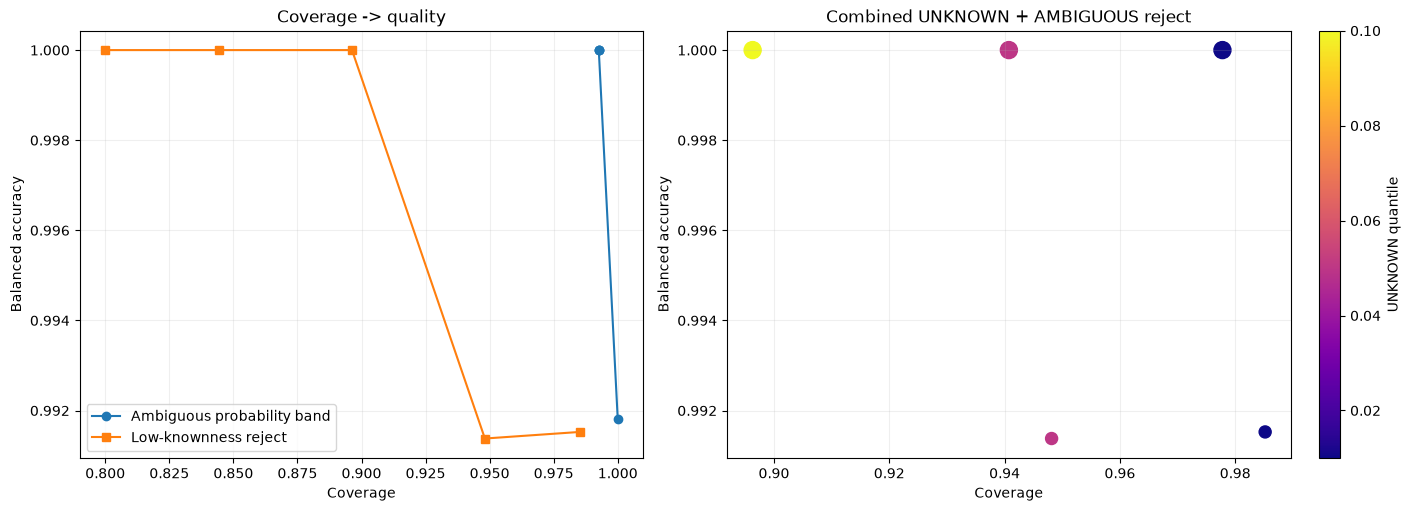

In [23]:
combined = pd.DataFrame(diagnostics['combined_reject'])
display(combined.style.format({'unknown_quantile': '{:.0%}', 'knownness_threshold': '{:.5f}', 'coverage': '{:.1%}', 'accuracy': '{:.3f}', 'balanced_accuracy': '{:.3f}', 'logging_precision': '{:.3f}', 'logging_recall': '{:.3f}', 'wildfire_precision': '{:.3f}', 'wildfire_recall': '{:.3f}'}))
display(diagnostic_plots['reject_curves'])
plt.close(diagnostic_plots['reject_curves'])

## 22. Frozen scoring of Hansen-mined events

The same frozen LogReg, manual kNN reference, PCA, and K-Means model are applied to Hansen events. HDBSCAN has no inductive prediction in this implementation, so Hansen status is inherited from the nearest manual POST event and must not be interpreted as an automatic UNKNOWN decision.

In [24]:
hansen_events = pd.DataFrame(diagnostics['hansen_rows'])
display(pd.DataFrame([{
    'events': len(hansen_events),
    'samples': hansen_events['sample_id'].nunique(),
    'UNKNOWN by manual p05': int(hansen_events['unknown_flag'].sum()),
    'AMBIGUOUS after UNKNOWN': int(hansen_events['ambiguous_flag'].sum()),
}]))
display(hansen_events[['event_id', 'event_year', 'logreg_probability_wildfire', 'knownness_k5', 'kmeans_cluster', 'hdbscan_cluster', 'unknown_flag', 'ambiguous_flag']].head(15))

,events,samples,UNKNOWN by manual p05,AMBIGUOUS after UNKNOWN
0,243,99,18,3


,event_id,event_year,logreg_probability_wildfire,knownness_k5,kmeans_cluster,hdbscan_cluster,unknown_flag,ambiguous_flag
0,80461db9d77577a5dcad4a6a1e6888ed22fa7896,2024,0.999959,0.808770,1,1,True,False
1,23406eae3754af33db372f120d8b24af9607a1f1,2025,0.999987,0.800936,1,-1,True,False
2,201a165e43eccd77c082f393e7fda3414de66eee,2020,0.996586,0.916935,1,1,False,False
3,4f8873247dda3943055315840c625f4e34e1932f,2021,0.999719,0.927837,2,1,False,False
4,060f8efb626dce7d148b658f5b4ebfad7a7d0be7,2023,0.000020,0.775324,2,-1,True,False
5,6fc1b20849f8ab7efe0ca516280b0dd794e4df84,2024,0.999988,0.922437,1,1,False,False
6,fff42ab958ed7d708961aebc08017664c0d3c709,2025,0.999937,0.935228,1,1,False,False
7,a90d138618aa6acfad616261e9acbc5bf47ff834,2017,0.999997,0.894118,1,1,False,False
8,449482e2dfe3ead25acb4cede9f679bb9dc68908,2018,0.999907,0.897389,1,1,False,False
9,53d342d8c7d3be3eb60785b9831162dfe4fbbdcf,2019,0.999982,0.887639,2,1,False,False


## 23. Manual-vs-Hansen domain shift

Quantiles, histograms, and ECDFs compare Hansen knownness with manual leave-one-out knownness. The direct p01/p05 test reports how many Hansen events fall below the corresponding manual reference tail.

,metric,manual_quantile,manual_threshold,hansen_below_events,hansen_below_share
0,knownness_k3,1%,0.81940,7,2.9%
1,knownness_k3,5%,0.86360,20,8.2%
2,knownness_k5,1%,0.80975,5,2.1%
3,knownness_k5,5%,0.85445,18,7.4%
4,knownness_k10,1%,0.79754,5,2.1%
5,knownness_k10,5%,0.83890,16,6.6%


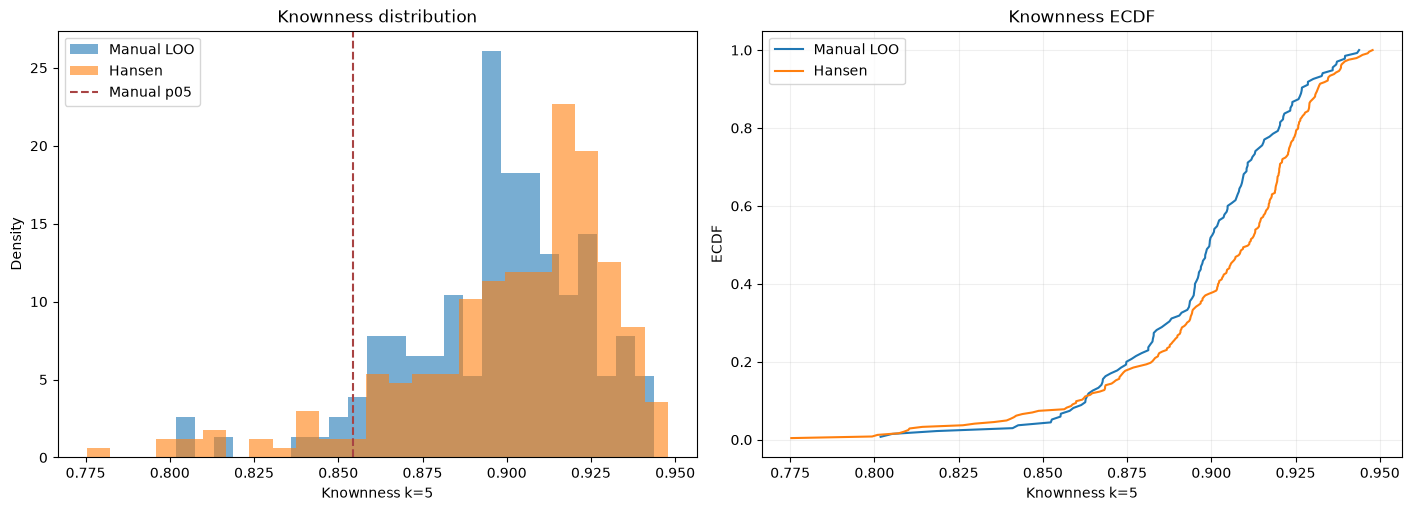

In [25]:
display(pd.DataFrame(diagnostics['train_hansen_quantiles']).pivot_table(index=['metric', 'quantile'], columns='source', values='value').style.format('{:.5f}'))
display(pd.DataFrame(diagnostics['domain_shift']).style.format({'manual_quantile': '{:.0%}', 'manual_threshold': '{:.5f}', 'hansen_below_share': '{:.1%}'}))
display(diagnostic_plots['train_hansen_knownness'])
plt.close(diagnostic_plots['train_hansen_knownness'])

## 24. RemoteCLIP × XGBoost interaction on Hansen events

The four model-interaction groups are compared by knownness, similarity margin, and LogReg probability. The RemoteCLIP=Logging / XGBoost=Wildfire group is additionally split into in-distribution Logging-like, ambiguous, OOD-by-manual-p05, and latent-conflict cases.

,agreement_type,events,knownness_k5_mean,knownness_k5_median,similarity_margin_mean,probability_wildfire_mean,unknown_share,ambiguous_share
0,AGREE_LOGGING,6,0.91870,0.91843,0.01747,0.0469,0.0%,0.0%
1,AGREE_WILDFIRE,184,0.90320,0.91395,0.02607,0.9750,7.6%,1.1%
2,RC_LOGGING_XGB_WILDFIRE,39,0.89122,0.90229,0.02309,0.1270,10.3%,2.6%
3,RC_WILDFIRE_XGB_LOGGING,14,0.90734,0.90810,0.01747,0.9993,0.0%,0.0%


,AMBIGUOUS_0_4_0_6,IN_DISTRIBUTION_LOGGING_LIKE,OOD_BY_MANUAL_P05,WILDFIRE_LIKE_LATENT_CONFLICT
0,1,27,4,7


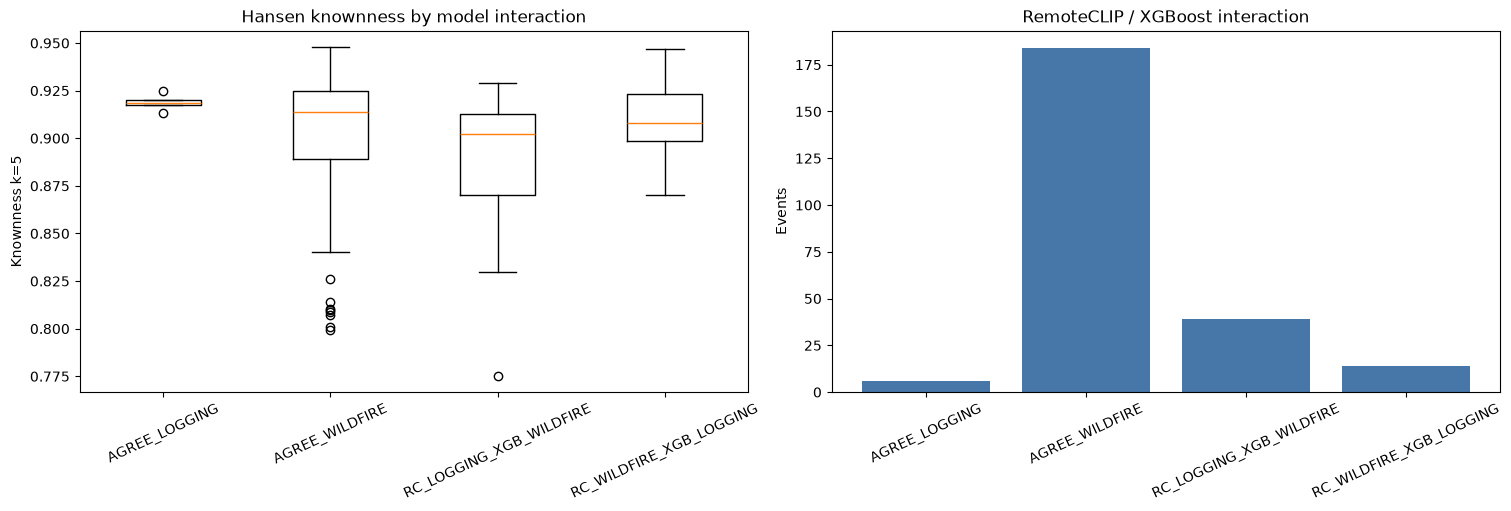

In [26]:
display(pd.DataFrame(diagnostics['hansen_group_summary']).style.format({'knownness_k5_mean': '{:.5f}', 'knownness_k5_median': '{:.5f}', 'similarity_margin_mean': '{:.5f}', 'probability_wildfire_mean': '{:.4f}', 'unknown_share': '{:.1%}', 'ambiguous_share': '{:.1%}'}))
display(pd.DataFrame([diagnostic_summary['rc_logging_xgb_wildfire_diagnosis']]).fillna(0))
display(diagnostic_plots['hansen_model_interaction'])
plt.close(diagnostic_plots['hansen_model_interaction'])

## 25. HDBSCAN noise diagnostics

Noise and clustered manual events are compared by LOO knownness and LogReg error. Noise remains a density diagnostic and is never converted directly to UNKNOWN.

,hdbscan_status,events,knownness_k5_mean,knownness_k5_median,logreg_error_rate
0,clustered,92,0.91055,0.90917,0.0%
1,noise,43,0.86810,0.87015,2.3%


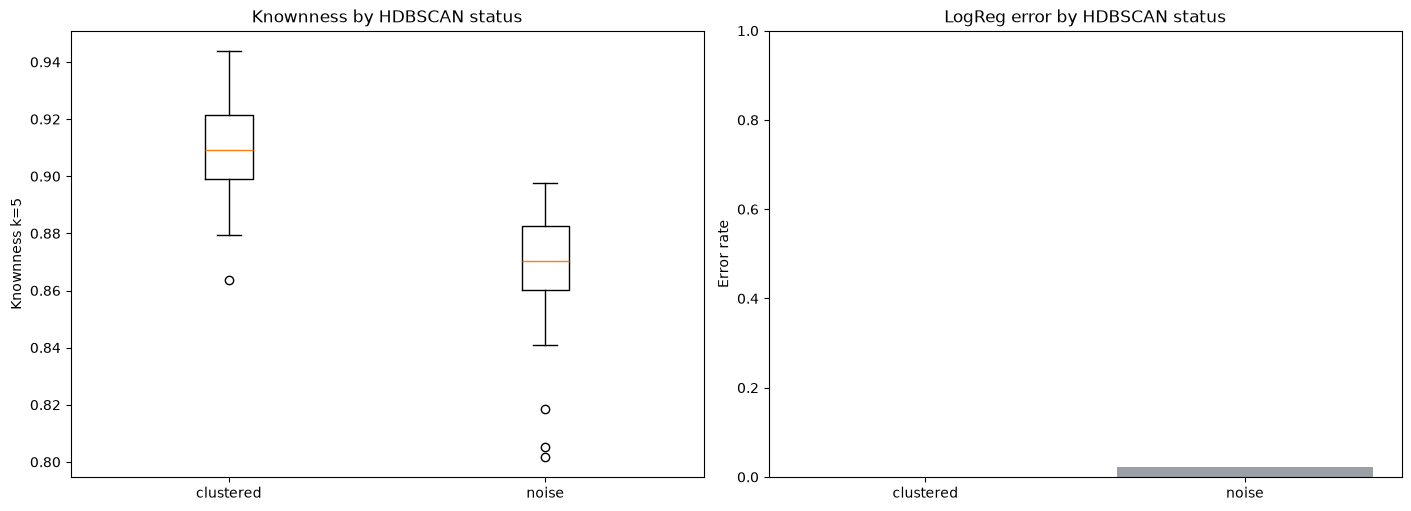

In [27]:
display(pd.DataFrame(diagnostics['hdbscan_noise_summary']).style.format({'knownness_k5_mean': '{:.5f}', 'knownness_k5_median': '{:.5f}', 'logreg_error_rate': '{:.1%}'}))
display(diagnostic_plots['hdbscan_noise'])
plt.close(diagnostic_plots['hdbscan_noise'])

## 26. kNN k-sensitivity

Spearman rank correlations compare knownness at `k=3,5,10`; Jaccard overlap compares the events in each low-knownness tail.

In [28]:
display(pd.DataFrame(diagnostics['knn_rank_stability']).style.format({'spearman_correlation': '{:.5f}', 'p_value': '{:.3g}'}))
display(pd.DataFrame(diagnostics['knn_unknown_overlap']).style.format({'bottom_fraction': '{:.0%}', 'jaccard': '{:.3f}'}))

,left_k,right_k,spearman_correlation,p_value
0,3,5,0.99029,7.26e-116
1,3,10,0.96621,3.52e-80
2,5,10,0.98853,4.6e-111


,left_k,right_k,bottom_fraction,events_per_set,intersection,jaccard
0,3,5,1%,2,2,1.000
1,3,5,5%,7,4,0.400
2,3,5,10%,14,11,0.647
3,3,5,15%,21,18,0.750
4,3,5,20%,27,24,0.800
5,3,10,1%,2,2,1.000
6,3,10,5%,7,3,0.273
7,3,10,10%,14,8,0.400
8,3,10,15%,21,16,0.615
9,3,10,20%,27,23,0.742


## 27. Event-level KMeans membership stability

K-Means k=3 is repeatedly refit on manual subsamples, aligned to the full-data solution with an optimal assignment, and predicted over all manual POST events. This measures whether individual events retain their mode.

,kmeans_cluster,events,membership_stability_mean,membership_stability_median,membership_stability_p10
0,0,45,94.5%,100.0%,85.0%
1,1,68,91.0%,100.0%,67.5%
2,2,36,97.6%,100.0%,91.3%


,event_id,sample_id,true_label,kmeans_cluster_raw,kmeans_cluster,membership_stability,runs
121,3063f614b8e33cb2d3e8c3e8cec79b49b896c365,d033a5b4c1a46fe6fc8e4c8abacc95ecc527b252,Logging,0,0,0.350,40
94,c50f83b5533e33193396246b9d629f8086b3daa4,af277c315a610f130a3744412fc514049e8cbdbc,Logging,0,0,0.350,40
114,0dc4d7065d3b0dca7f1d147c557912f3329fd1b4,c8592ec23038bcf50d4c0cb9e15410fbd565dda5,Wildfire,1,1,0.375,40
50,1b399c5b00ed658df1360e265fe61e5511e6a28d,580d600a211e12445f6da9bea3e40d165bdd4275,Wildfire,1,1,0.450,40
22,59afd76438f7695b7a0d8408202d28372c272fe4,21e9140e47e984b128e7842b364f8dc04b6fb77d,Logging,0,0,0.475,40
92,f3ef228e05d7a7488a3f8720abc5abe1e683f9de,ad3f88fdce7490f42a6961c9ddcf0cb96d63d89e,Logging,1,1,0.500,40
7,d567025fc66305761627192faf469d6905c9fe26,1098e1fc8b4ff1cc29d373b1366b1d69fa0762bb,Wildfire,1,1,0.500,40
31,18ba16ffb78d7045f7360af6622624f471f4b0dd,2c33ffed48d98c7ec377222147a5e42e46eda320,Wildfire,1,1,0.600,40
97,734db5c14c0dce5995564233fb3b4e401b4fcf3a,b15d9afa8011e6e15817c531799c03d4060fffa1,Wildfire,1,1,0.625,40
113,c225d1710f7c75cfe9d8b5b5ecaf94d0fd459a28,c7fae4986437d8b806bc93b11290126f65d5852a,Logging,0,0,0.625,40


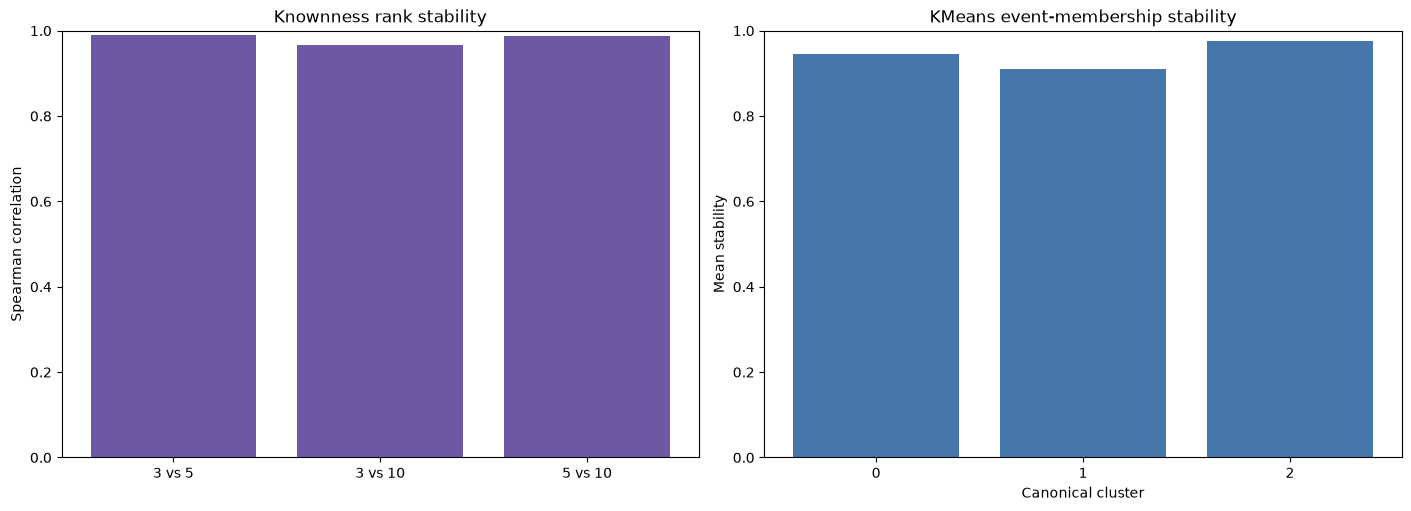

In [29]:
display(pd.DataFrame(diagnostics['membership_stability_summary']).style.format({'membership_stability_mean': '{:.1%}', 'membership_stability_median': '{:.1%}', 'membership_stability_p10': '{:.1%}'}))
display(pd.DataFrame(diagnostics['membership_stability']).sort_values('membership_stability').head(20))
display(diagnostic_plots['stability_diagnostics'])
plt.close(diagnostic_plots['stability_diagnostics'])

## 28. Combined event-level export

The final table joins manual and Hansen events with frozen model probability, cluster assignments, HDBSCAN status, three knownness scales, class similarities, diagnostic reject flags, both model predictions, and agreement type. The full CSV is saved as `latent_event_level_table.csv`.

In [30]:
event_level = pd.DataFrame(diagnostics['final_rows'])
display(event_level.groupby(['source', 'agreement_type'], dropna=False).size().rename('events').reset_index())
display(event_level.head(20))
pipeline.run_dir / 'latent_event_level_table.csv'

,source,agreement_type,events
0,HANSEN_MINED,AGREE_LOGGING,6
1,HANSEN_MINED,AGREE_WILDFIRE,184
2,HANSEN_MINED,RC_LOGGING_XGB_WILDFIRE,39
3,HANSEN_MINED,RC_WILDFIRE_XGB_LOGGING,14
4,MANUAL_TRAIN,REMOTECLIP_ONLY,135


,source,sample_id,event_id,event_year,season,true_label,logreg_probability_wildfire,kmeans_cluster,kmeans_cluster_raw,kmeans_cluster_role,...,remoteclip_prediction,xgboost_prediction,agreement_type,is_multi_event_area,event_loss_area_ha,pre_image_count,post_image_count,hansen_event_count,hansen_event_years,cluster_membership_stability
0,MANUAL_TRAIN,014ebcfa8c4c4e37669da9360bb2f7d33ecad401,f0ea8245f0e531ddf93a9efbd9dfdfd70c78d29e,2021,outside_defined_seasons,Wildfire,0.998849,2,2,mixed_mode,...,Wildfire,,REMOTECLIP_ONLY,False,73.4378,2,3,1,[2021],1.000
1,MANUAL_TRAIN,03729ae3b0bec34e691900e592270d87a31d71db,9db54f6a5d220c39ea506e4bafd413b09b083779,2024,late_summer,Wildfire,0.999874,1,1,wildfire_mode,...,Wildfire,,REMOTECLIP_ONLY,False,95.3622,2,7,2,"[2024, 2025]",1.000
2,MANUAL_TRAIN,05d5126ea7bf1e23249a4315161430b5677f91c8,99c9f3e316febfea8141f579cbb8886e2494d2a8,2024,early_summer,Wildfire,0.999998,1,1,wildfire_mode,...,Wildfire,,REMOTECLIP_ONLY,False,72.6355,6,3,2,"[2024, 2025]",1.000
3,MANUAL_TRAIN,0633c87245d4f0e672ff4dd3cc591d01615699b0,0dcf70a85c9be384bd23dcfdee590d5c484047a8,2017,early_summer,Wildfire,0.404948,2,2,mixed_mode,...,Logging,,REMOTECLIP_ONLY,False,2.9316,2,3,2,"[2016, 2017]",0.975
4,MANUAL_TRAIN,08e304d71c79798ce963684f552ac141b79e6f5e,42868dae7542a4b917b4764815a342474e7468c4,2024,late_summer,Wildfire,0.991866,2,2,mixed_mode,...,Wildfire,,REMOTECLIP_ONLY,False,22.8206,6,7,2,"[2024, 2025]",1.000
5,MANUAL_TRAIN,0a1d1a56ea189abd64fe1ba2496178050a9a9c0f,7a2033025cb30d007f309d8c947457ff57c535cc,2020,early_summer,Logging,0.000054,0,0,logging_mode,...,Logging,,REMOTECLIP_ONLY,True,11.3805,1,5,6,"[2016, 2017, 2020, 2021, 2022, 2025]",1.000
6,MANUAL_TRAIN,1098e1fc8b4ff1cc29d373b1366b1d69fa0762bb,d567025fc66305761627192faf469d6905c9fe26,2021,early_summer,Wildfire,0.996095,1,1,wildfire_mode,...,Wildfire,,REMOTECLIP_ONLY,False,45.4648,4,4,2,"[2020, 2021]",0.500
7,MANUAL_TRAIN,12fb91c579cb98d698ed564cafab002a8735a4a7,7233ce5ad3a5bbdbcc13e990ee3cb6ea4ea190e6,2021,late_summer,Logging,0.000091,2,2,mixed_mode,...,Logging,,REMOTECLIP_ONLY,True,11.4748,3,3,3,"[2021, 2022, 2025]",1.000
8,MANUAL_TRAIN,1460cd7355fb4dfb878677df9787f4c7fef8052f,9e8f8d68ce5f4f35595c51d17be23f0e3554b54f,2025,early_summer,Logging,0.000637,0,0,logging_mode,...,Logging,,REMOTECLIP_ONLY,False,16.4305,1,6,1,[2025],1.000
9,MANUAL_TRAIN,14af5b0465df00acdc96db5c47edff30a242cd61,42d5f846cc3f7c9043b94c81f3c7538a9c62a19d,2017,outside_defined_seasons,Wildfire,0.999798,1,1,wildfire_mode,...,Wildfire,,REMOTECLIP_ONLY,True,52.4925,1,1,4,"[2017, 2018, 2019, 2020]",1.000


WindowsPath('C:/Users/Hp/OneDrive/Рабочий стол/учёба/ML/ML-SbPSTU-2026/Scripts/ResearchScripts/Outputs/ml_experiments/20261101_155425/latent_event_level_table.csv')

## 29. Human-readable Markdown report

The pipeline composes the cohort audit, cluster structure, knownness reference, reject curves, domain-shift checks, model interaction, and stability diagnostics into one `REPORT.md`. The report is generated from the same in-memory result as the CSV files, so no values are copied by hand.

In [ ]:
report_path = diagnostics['report_path']
display(Markdown(report_path.read_text(encoding='utf-8')))
report_path

## 30. Saved artifacts

The run directory contains the event-level cluster assignments, every metric table, the full HDBSCAN sweep, stability runs, a compact JSON report, and PNG figures. Reopening the notebook does not invalidate the embedding cache; unchanged images and model fingerprints produce cache hits.

In [31]:
sorted(str(path.relative_to(pipeline.run_dir)) for path in pipeline.run_dir.rglob('*') if path.is_file())

['cohort_distribution.csv',
 'config.json',
 'dataset_audit.json',
 'dataset_manifest.csv',
 'embedding_cache_report.json',
 'embedding_cache_rows.csv',
 'event_backfill_plan.csv',
 'event_backfill_plan.json',
 'latent_ambiguity_reject.csv',
 'latent_cluster_label_multi_event.csv',
 'latent_cluster_label_season.csv',
 'latent_cluster_roles.csv',
 'latent_combined_reject.csv',
 'latent_diagnostics_summary.json',
 'latent_domain_shift.csv',
 'latent_event_level_table.csv',
 'latent_hansen_events.csv',
 'latent_hansen_model_interaction.csv',
 'latent_hdbscan_noise.csv',
 'latent_knn_rank_stability.csv',
 'latent_knn_unknown_overlap.csv',
 'latent_knownness_reject.csv',
 'latent_loo_knownness_quantiles.csv',
 'latent_manual_events.csv',
 'latent_membership_stability.csv',
 'latent_membership_stability_runs.csv',
 'latent_membership_stability_summary.csv',
 'latent_mode_comparison.csv',
 'latent_mode_seasons.csv',
 'latent_probability_by_cluster.csv',
 'latent_probability_correlations.csv',